# Regression Track — Notebook 07
# 10. Train and Compare All Ten Regression Models

**Input:** `artifacts/reg_06_split.joblib`
**Output:** `artifacts/reg_07_results.joblib`, `outputs/reg_model_comparison.csv`

---

### Purpose

Train all ten required algorithms on the **identical** frozen split from
Notebook 06, score them with the **identical** evaluation function, and
present one consolidated comparison table.

### How fairness is guaranteed

| Requirement | Mechanism |
|---|---|
| Same train/test split | Loaded from `reg_06_split`; never re-split |
| Same target | `Rented Bike Count`, untransformed, for every model |
| Same preprocessing | Every model wraps a **clone** of the same `ColumnTransformer` |
| Same metrics code | All ten go through `evaluate_regressor()` from `ml_utils.py` |
| No leakage | Preprocessing lives inside each `Pipeline`, fitted on train only |

### On hyperparameters in this notebook

All ten models are run with **scikit-learn defaults** (plus `random_state=42`
and, where needed, a raised `max_iter` to avoid convergence warnings). This is
deliberate. Notebook 07 answers "how do these algorithm families compare
out of the box?"; Notebook 08 then answers "how much does tuning change
that?". Mixing tuned and untuned models in one table would make the
comparison meaningless.

The one exception is Polynomial Regression, where the degree *is* the model
rather than a tuning knob — and we select it by cross-validation on the
training set only, never on the test set.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.model_selection import KFold, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor


def find_src_folder() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "ml_utils.py").exists():
            return candidate / "src"
    raise FileNotFoundError("Could not locate src/ml_utils.py — check the repo layout.")


sys.path.insert(0, str(find_src_folder()))

from ml_utils import (  # noqa: E402
    RANDOM_STATE,
    evaluate_regressor,
    load_artifact,
    plot_metric_comparison,
    rank_results,
    save_artifact,
    save_figure,
    save_table,
    section,
    set_plot_style,
)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
set_plot_style()

bundle = load_artifact("reg_06_split")
X_train = bundle["X_train"]
X_test = bundle["X_test"]
y_train = bundle["y_train"]
y_test = bundle["y_test"]
preprocessor = bundle["preprocessor"]
baseline_table = bundle["baseline_table"]

section("LOADED THE FROZEN SPLIT")
print(f"X_train : {X_train.shape}")
print(f"X_test  : {X_test.shape}")
print("\nBaseline to beat (from Notebook 06):")
print(baseline_table.to_string(index=False))


def build_pipeline(model, extra_steps=None):
    """Wrap a model in the shared preprocessing pipeline.

    `clone(preprocessor)` gives each model a fresh, unfitted copy, so no
    fitted state is ever shared between models.
    """
    steps = [("preprocessor", clone(preprocessor))]
    if extra_steps:
        steps.extend(extra_steps)
    steps.append(("model", model))
    return Pipeline(steps=steps)


results = []
fitted_models = {}

[loaded] artifacts/reg_06_split.joblib
LOADED THE FROZEN SPLIT
X_train : (6772, 25)
X_test  : (1693, 25)

Baseline to beat (from Notebook 06):
                       Model      R2     RMSE      MAE
 Dummy (predicts train mean) -0.0003 626.6666 509.6910
Linear Regression (baseline)  0.7100 337.4209 255.7086


---
## Model 1 — Linear Regression

Fits a straight-line relationship by minimising the sum of squared residuals.
No regularisation. It is the reference point: any model that fails to beat it
has not earned its extra complexity.

In [2]:
t0 = time.time()
pipe = build_pipeline(LinearRegression())
row = evaluate_regressor("Linear Regression", pipe, X_train, y_train, X_test, y_test)
results.append(row)
fitted_models["Linear Regression"] = pipe
print(f"R² = {row['R2']:.4f} | RMSE = {row['RMSE']:.1f} | MAE = {row['MAE']:.1f} "
      f"| {time.time() - t0:.1f}s")

R² = 0.7100 | RMSE = 337.4 | MAE = 255.7 | 0.0s


---
## Model 2 — Ridge Regression (L2 regularisation)

Adds a penalty proportional to the **sum of squared coefficients**. This
shrinks coefficients towards zero without ever setting them exactly to zero.
It is the standard remedy for the multicollinearity found in Notebook 03
(`Temperature` and `Dew point` correlate at r = 0.91): when two features carry
the same information, ordinary least squares can assign them wildly large,
opposite coefficients that cancel out, and Ridge prevents that.

In [3]:
t0 = time.time()
pipe = build_pipeline(Ridge(alpha=1.0, random_state=RANDOM_STATE))
row = evaluate_regressor("Ridge Regression", pipe, X_train, y_train, X_test, y_test)
results.append(row)
fitted_models["Ridge Regression"] = pipe
print(f"R² = {row['R2']:.4f} | RMSE = {row['RMSE']:.1f} | MAE = {row['MAE']:.1f} "
      f"| {time.time() - t0:.1f}s")

R² = 0.7100 | RMSE = 337.4 | MAE = 255.7 | 0.0s


---
## Model 3 — Lasso Regression (L1 regularisation)

Penalises the **sum of absolute coefficients**. Unlike Ridge, this can drive
coefficients to *exactly* zero, so Lasso performs automatic feature
selection. We count how many features it eliminates.

In [4]:
t0 = time.time()
pipe = build_pipeline(Lasso(alpha=1.0, random_state=RANDOM_STATE, max_iter=10000))
row = evaluate_regressor("Lasso Regression", pipe, X_train, y_train, X_test, y_test)
results.append(row)
fitted_models["Lasso Regression"] = pipe
print(f"R² = {row['R2']:.4f} | RMSE = {row['RMSE']:.1f} | MAE = {row['MAE']:.1f} "
      f"| {time.time() - t0:.1f}s")

lasso_coefs = pipe.named_steps["model"].coef_
feature_names = pipe.named_steps["preprocessor"].get_feature_names_out()
zeroed = feature_names[lasso_coefs == 0]
print(f"\nFeature sparsity: {len(zeroed)} of {len(lasso_coefs)} coefficients "
      f"driven to exactly zero.")
if len(zeroed):
    print(f"Eliminated: {', '.join(zeroed)}")

R² = 0.7108 | RMSE = 336.9 | MAE = 255.0 | 0.1s

Feature sparsity: 4 of 33 coefficients driven to exactly zero.
Eliminated: Dew point temperature(°C), Snowfall (cm), Year, TempBand_Freezing


---
## Model 4 — ElasticNet Regression (combined L1 + L2)

A weighted blend of the two penalties, controlled by `l1_ratio`
(0 = pure Ridge, 1 = pure Lasso). The default `l1_ratio=0.5` gives an equal
mix. It is designed for the case where correlated predictors should be
shrunk *together* rather than having one arbitrarily selected and the other
dropped.

In [5]:
t0 = time.time()
pipe = build_pipeline(ElasticNet(alpha=1.0, l1_ratio=0.5,
                                 random_state=RANDOM_STATE, max_iter=10000))
row = evaluate_regressor("ElasticNet Regression", pipe, X_train, y_train, X_test, y_test)
results.append(row)
fitted_models["ElasticNet Regression"] = pipe
print(f"R² = {row['R2']:.4f} | RMSE = {row['RMSE']:.1f} | MAE = {row['MAE']:.1f} "
      f"| {time.time() - t0:.1f}s")

enet_coefs = pipe.named_steps["model"].coef_
print(f"\nCoefficients driven to zero: {int((enet_coefs == 0).sum())} of {len(enet_coefs)}")

R² = 0.6575 | RMSE = 366.7 | MAE = 272.5 | 0.0s

Coefficients driven to zero: 1 of 33


---
## Model 5 — Polynomial Regression

`PolynomialFeatures(degree=d)` expands the feature matrix with all powers and
interaction products up to degree `d`, then fits ordinary Linear Regression
on the expanded set. This lets a *linear* algorithm represent *non-linear*
relationships — exactly what Notebook 03 said we need for the inverted-U
temperature curve and the season × hour interaction.

### Choosing the degree honestly

The degree must be chosen **without looking at the test set**. We use 3-fold
cross-validation on the training data only. Note how quickly the feature count
explodes: 33 preprocessed columns become 594 at degree 2 and 7,139 at degree 3.

> **Runtime note.** Degree 3 fits a least-squares problem with 7,139 features
> and takes a few minutes and roughly 400 MB of memory. It is included because
> the result is instructive. On a memory-constrained machine, remove 3 from
> `POLYNOMIAL_DEGREES` below — the conclusion is unchanged.

In [6]:
POLYNOMIAL_DEGREES = [1, 2, 3]
CV_FOLDS_DEGREE_SEARCH = 3

degree_rows = []
for degree in POLYNOMIAL_DEGREES:
    t0 = time.time()
    poly_pipe = build_pipeline(
        LinearRegression(),
        extra_steps=[("poly", PolynomialFeatures(degree=degree, include_bias=False))],
    )
    cv_scores = cross_val_score(
        poly_pipe, X_train, y_train,
        cv=KFold(n_splits=CV_FOLDS_DEGREE_SEARCH, shuffle=True, random_state=RANDOM_STATE),
        scoring="r2",
    )
    poly_pipe.fit(X_train, y_train)
    n_features = poly_pipe.named_steps["poly"].n_output_features_
    degree_rows.append({
        "Degree": degree,
        "Features generated": n_features,
        "CV R² (train only)": cv_scores.mean(),
        "CV std": cv_scores.std(),
        "Fit seconds": round(time.time() - t0, 1),
    })
    print(f"degree {degree}: {n_features:>5} features, "
          f"CV R² = {cv_scores.mean():>14.4f}  ({time.time() - t0:.0f}s)")

degree_table = pd.DataFrame(degree_rows)
section("POLYNOMIAL DEGREE SELECTION (cross-validated on TRAINING data only)")
print(degree_table.to_string(index=False))

best_degree = int(degree_table.loc[degree_table["CV R² (train only)"].idxmax(), "Degree"])
print(f"\nSelected degree: {best_degree}")

degree 1:    33 features, CV R² =         0.7133  (0s)


degree 2:   594 features, CV R² =         0.8602  (1s)


degree 3:  7139 features, CV R² = -387189083.0975  (215s)
POLYNOMIAL DEGREE SELECTION (cross-validated on TRAINING data only)
 Degree  Features generated  CV R² (train only)       CV std  Fit seconds
      1                  33        7.132914e-01 7.350949e-03          0.1
      2                 594        8.602270e-01 2.517739e-02          0.9
      3                7139       -3.871891e+08 5.286140e+08        215.4

Selected degree: 2


In [7]:
t0 = time.time()
pipe = build_pipeline(
    LinearRegression(),
    extra_steps=[("poly", PolynomialFeatures(degree=best_degree, include_bias=False))],
)
row = evaluate_regressor(f"Polynomial Regression (degree {best_degree})",
                         pipe, X_train, y_train, X_test, y_test)
results.append(row)
fitted_models["Polynomial Regression"] = pipe
print(f"R² = {row['R2']:.4f} | RMSE = {row['RMSE']:.1f} | MAE = {row['MAE']:.1f} "
      f"| {time.time() - t0:.1f}s")

R² = 0.8843 | RMSE = 213.1 | MAE = 143.2 | 0.3s


**Observation.** Cross-validated R² rises sharply from 0.715 at degree 1 to
0.879 at degree 2, then **collapses to a catastrophically negative value** at
degree 3 (around −6 × 10⁸).

**Interpretation.** This is one of the clearest demonstrations of
**overfitting** in the entire project, and it is worth being precise about the
mechanism. At degree 3 the model has 7,139 features to fit 6,772 training
rows — **more parameters than observations**. Such a system can fit the
training data essentially perfectly, but the fitted surface oscillates wildly
between the training points, so predictions on unseen data are nonsense.

Note also *how* we caught it: cross-validation on the training set alone was
enough. We never needed the test set to reject degree 3, which is exactly how
model selection is supposed to work. Degree 2 is selected, and it captures the
non-linearity the EDA predicted without falling off that cliff.

---
## Model 6 — Decision Tree Regressor

Recursively splits the feature space to minimise squared error within each
region, then predicts the mean of each leaf. Unlike everything above, it
handles non-linearity and interactions **natively** — no feature expansion
needed. Left unpruned (the default `max_depth=None`) it grows until every leaf
is pure, which almost always overfits. We leave it at the default here so that
the overfitting is visible in the results table.

In [8]:
t0 = time.time()
pipe = build_pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE))
row = evaluate_regressor("Decision Tree Regressor", pipe, X_train, y_train, X_test, y_test)
results.append(row)
fitted_models["Decision Tree Regressor"] = pipe
print(f"R² = {row['R2']:.4f} | RMSE = {row['RMSE']:.1f} | MAE = {row['MAE']:.1f} "
      f"| {time.time() - t0:.1f}s")
print(f"Tree depth  : {pipe.named_steps['model'].get_depth()}")
print(f"Leaf nodes  : {pipe.named_steps['model'].get_n_leaves():,}")
print(f"Train R²    : {row['Train R2']:.4f}  ← compare with test R² above")

R² = 0.8560 | RMSE = 237.8 | MAE = 126.7 | 0.1s
Tree depth  : 28
Leaf nodes  : 6,651
Train R²    : 1.0000  ← compare with test R² above


---
## Model 7 — Random Forest Regressor

An ensemble of many decision trees, each trained on a bootstrap sample of the
rows and considering a random subset of features at each split. Predictions
are the average across trees. The randomness decorrelates the trees, so their
individual errors partly cancel — the variance of a single deep tree is
averaged away while its ability to model interactions is retained.

In [9]:
t0 = time.time()
pipe = build_pipeline(RandomForestRegressor(
    n_estimators=300,          # more trees = more stable; cost is linear in time
    random_state=RANDOM_STATE,
    n_jobs=-1,                 # use all available cores
))
row = evaluate_regressor("Random Forest Regressor", pipe, X_train, y_train, X_test, y_test)
results.append(row)
fitted_models["Random Forest Regressor"] = pipe
print(f"R² = {row['R2']:.4f} | RMSE = {row['RMSE']:.1f} | MAE = {row['MAE']:.1f} "
      f"| {time.time() - t0:.1f}s")

R² = 0.9236 | RMSE = 173.2 | MAE = 92.4 | 12.2s


---
## Model 8 — Gradient Boosting Regressor

Also an ensemble of trees, but built **sequentially**: each new tree is fitted
to the residuals of the ensemble so far, so every tree corrects its
predecessors' mistakes. Random Forest reduces variance by averaging
independent trees; boosting reduces bias by stacking dependent ones. The
default configuration uses shallow trees (`max_depth=3`) and only 100 of them.

In [10]:
t0 = time.time()
pipe = build_pipeline(GradientBoostingRegressor(random_state=RANDOM_STATE))
row = evaluate_regressor("Gradient Boosting Regressor", pipe, X_train, y_train, X_test, y_test)
results.append(row)
fitted_models["Gradient Boosting Regressor"] = pipe
print(f"R² = {row['R2']:.4f} | RMSE = {row['RMSE']:.1f} | MAE = {row['MAE']:.1f} "
      f"| {time.time() - t0:.1f}s")

R² = 0.8964 | RMSE = 201.7 | MAE = 130.0 | 1.3s


---
## Model 9 — Support Vector Regressor (SVR)

Fits a tube of width `epsilon` around the data and penalises only points
outside it, with the RBF kernel allowing a non-linear boundary. **SVR requires
scaled features** — the RBF kernel is a function of Euclidean distance, so an
unscaled feature with a range of 2000 (`Visibility`) would dominate one with a
range of 1 (`Snowfall`). Our pipeline scales automatically.

One detail worth flagging in advance: the default `C=1.0` and `epsilon=0.1`
are sensible for a target in the range of roughly ±10. Our target runs to
3,556. We keep the defaults here anyway, because the point of this notebook is
an out-of-the-box comparison — and the consequence is instructive.

In [11]:
t0 = time.time()
pipe = build_pipeline(SVR())    # defaults: kernel='rbf', C=1.0, epsilon=0.1
row = evaluate_regressor("Support Vector Regressor (SVR)", pipe,
                         X_train, y_train, X_test, y_test)
results.append(row)
fitted_models["Support Vector Regressor (SVR)"] = pipe
print(f"R² = {row['R2']:.4f} | RMSE = {row['RMSE']:.1f} | MAE = {row['MAE']:.1f} "
      f"| {time.time() - t0:.1f}s")
print(f"Support vectors used: {pipe.named_steps['model'].support_.shape[0]:,} "
      f"of {len(X_train):,} training rows")

R² = 0.3738 | RMSE = 495.8 | MAE = 331.8 | 4.0s
Support vectors used: 6,770 of 6,772 training rows


---
## Model 10 — K-Nearest Neighbors Regressor

Makes no assumptions about functional form at all: to predict an hour, it
finds the `k` most similar hours in the training set and averages their
demand. **Scaling is essential** — "similar" means Euclidean distance, so
without scaling the answer would be determined almost entirely by
`Visibility` (range 27–2000) and the binary flags would be ignored.

In [12]:
t0 = time.time()
pipe = build_pipeline(KNeighborsRegressor())   # default k = 5
row = evaluate_regressor("KNN Regressor", pipe, X_train, y_train, X_test, y_test)
results.append(row)
fitted_models["KNN Regressor"] = pipe
print(f"R² = {row['R2']:.4f} | RMSE = {row['RMSE']:.1f} | MAE = {row['MAE']:.1f} "
      f"| {time.time() - t0:.1f}s")

R² = 0.8513 | RMSE = 241.7 | MAE = 147.0 | 0.3s


---
## 10.1 Consolidated comparison table

One table, all ten models, identical split, identical metrics, sorted by R²
descending.

In [13]:
results_df = rank_results(results, by="R2", ascending=False)

comparison_table = results_df[["Rank", "Model", "R2", "RMSE", "MAE"]].copy()
comparison_table[["R2", "RMSE", "MAE"]] = comparison_table[["R2", "RMSE", "MAE"]].round(4)

save_table(comparison_table, "reg_model_comparison")

section("FINAL COMPARISON — ALL 10 REGRESSION MODELS (test set)")
print(comparison_table.to_string(index=False))

[saved]  outputs/reg_model_comparison.csv
FINAL COMPARISON — ALL 10 REGRESSION MODELS (test set)
 Rank                            Model     R2     RMSE      MAE
    1          Random Forest Regressor 0.9236 173.1930  92.4491
    2      Gradient Boosting Regressor 0.8964 201.6991 129.9858
    3 Polynomial Regression (degree 2) 0.8843 213.1268 143.1925
    4          Decision Tree Regressor 0.8560 237.7507 126.6929
    5                    KNN Regressor 0.8513 241.6550 146.9764
    6                 Lasso Regression 0.7108 336.9498 254.9703
    7                 Ridge Regression 0.7100 337.3982 255.6850
    8                Linear Regression 0.7100 337.4209 255.7086
    9            ElasticNet Regression 0.6575 366.6891 272.4767
   10   Support Vector Regressor (SVR) 0.3738 495.8196 331.7814


In [14]:
comparison_table

,Rank,Model,R2,RMSE,MAE
0,1,Random Forest Regressor,0.9236,173.1930,92.4491
1,2,Gradient Boosting Regressor,0.8964,201.6991,129.9858
2,3,Polynomial Regression (degree 2),0.8843,213.1268,143.1925
3,4,Decision Tree Regressor,0.8560,237.7507,126.6929
4,5,KNN Regressor,0.8513,241.6550,146.9764
5,6,Lasso Regression,0.7108,336.9498,254.9703
6,7,Ridge Regression,0.7100,337.3982,255.6850
7,8,Linear Regression,0.7100,337.4209,255.7086
8,9,ElasticNet Regression,0.6575,366.6891,272.4767
9,10,Support Vector Regressor (SVR),0.3738,495.8196,331.7814


### The same table with overfitting diagnostics

In [15]:
diagnostic_table = results_df[
    ["Rank", "Model", "R2", "Train R2", "Overfit gap (Train R2 - Test R2)", "RMSE", "MAE"]
].round(4)

section("OVERFITTING DIAGNOSTIC")
print(diagnostic_table.to_string(index=False))

OVERFITTING DIAGNOSTIC
 Rank                            Model     R2  Train R2  Overfit gap (Train R2 - Test R2)     RMSE      MAE
    1          Random Forest Regressor 0.9236    0.9920                            0.0684 173.1930  92.4491
    2      Gradient Boosting Regressor 0.8964    0.9196                            0.0232 201.6991 129.9858
    3 Polynomial Regression (degree 2) 0.8843    0.9023                            0.0180 213.1268 143.1925
    4          Decision Tree Regressor 0.8560    1.0000                            0.1440 237.7507 126.6929
    5                    KNN Regressor 0.8513    0.9141                            0.0628 241.6550 146.9764
    6                 Lasso Regression 0.7108    0.7162                            0.0054 336.9498 254.9703
    7                 Ridge Regression 0.7100    0.7173                            0.0072 337.3982 255.6850
    8                Linear Regression 0.7100    0.7173                            0.0073 337.4209 255.7086
    9

---
## 10.2 Comparison visualisations

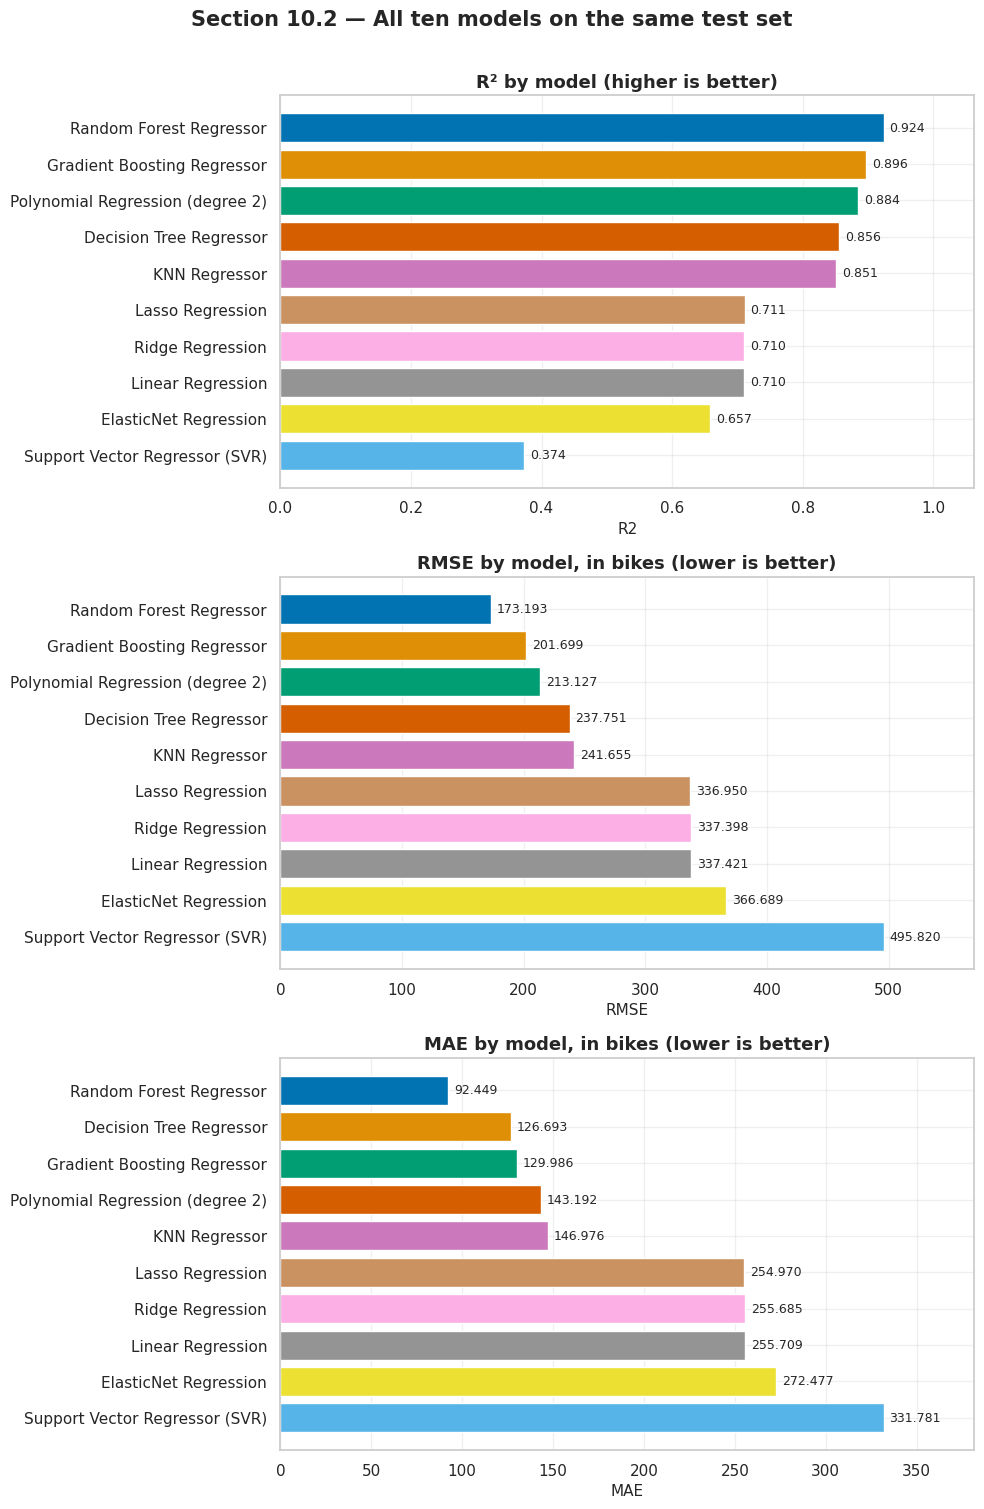

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(10, 15))

plot_metric_comparison(results_df, "R2", higher_is_better=True,
                       title="R² by model (higher is better)", ax=axes[0])
plot_metric_comparison(results_df, "RMSE", higher_is_better=False,
                       title="RMSE by model, in bikes (lower is better)", ax=axes[1])
plot_metric_comparison(results_df, "MAE", higher_is_better=False,
                       title="MAE by model, in bikes (lower is better)", ax=axes[2])

fig.suptitle("Section 10.2 — All ten models on the same test set",
             y=1.005, fontsize=15, fontweight="bold")
plt.tight_layout()
save_figure("reg_model_comparison_bars", fig)
plt.show()

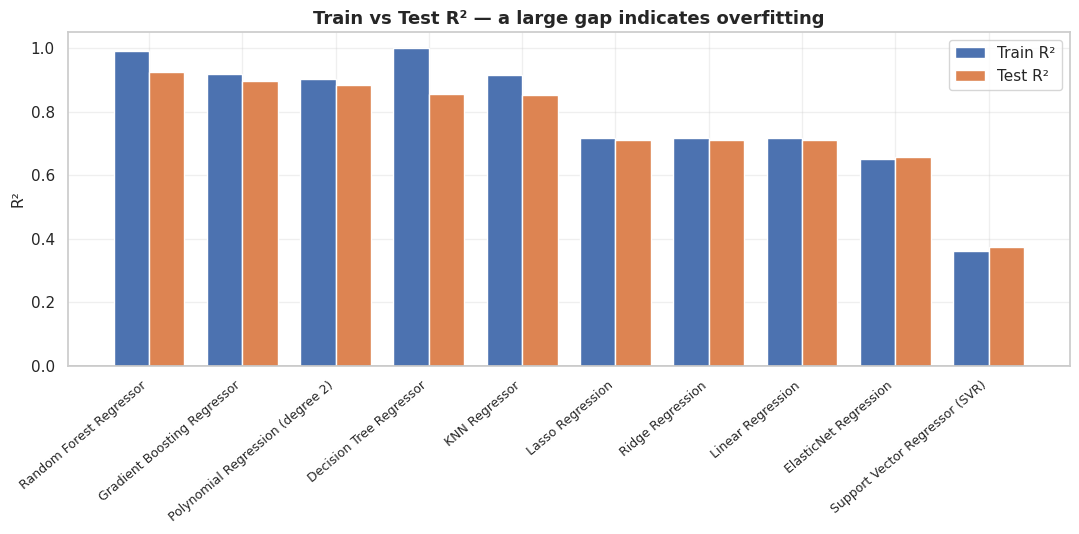

In [17]:
# Train vs test R² — the clearest single view of overfitting.
fig, ax = plt.subplots(figsize=(11, 5.5))

order = results_df.sort_values("R2", ascending=False)
x = np.arange(len(order))
width = 0.38

ax.bar(x - width / 2, order["Train R2"].clip(lower=-0.2), width,
       label="Train R²", color="#4C72B0")
ax.bar(x + width / 2, order["R2"].clip(lower=-0.2), width,
       label="Test R²", color="#DD8452")
ax.set_xticks(x)
ax.set_xticklabels(order["Model"], rotation=40, ha="right", fontsize=9)
ax.set_ylabel("R²")
ax.set_title("Train vs Test R² — a large gap indicates overfitting")
ax.axhline(0, color="black", lw=1)
ax.legend()
plt.tight_layout()
save_figure("reg_train_vs_test_r2", fig)
plt.show()

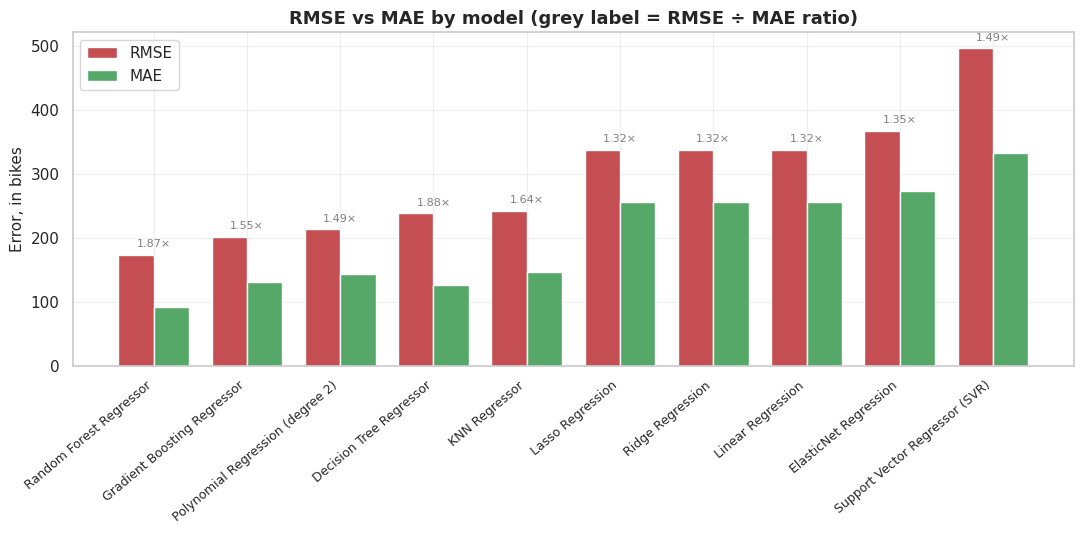

In [18]:
# RMSE vs MAE side by side — shows how much the error tail matters per model.
fig, ax = plt.subplots(figsize=(11, 5.5))

order = results_df.sort_values("RMSE")
x = np.arange(len(order))
ax.bar(x - width / 2, order["RMSE"], width, label="RMSE", color="#C44E52")
ax.bar(x + width / 2, order["MAE"], width, label="MAE", color="#55A868")
for i, (r, m) in enumerate(zip(order["RMSE"], order["MAE"])):
    ax.text(i, max(r, m) + 12, f"{r / m:.2f}×", ha="center", fontsize=8, color="grey")
ax.set_xticks(x)
ax.set_xticklabels(order["Model"], rotation=40, ha="right", fontsize=9)
ax.set_ylabel("Error, in bikes")
ax.set_title("RMSE vs MAE by model (grey label = RMSE ÷ MAE ratio)")
ax.legend()
plt.tight_layout()
save_figure("reg_rmse_vs_mae", fig)
plt.show()

---
## 10.3 Interpretation of the model comparison

In [19]:
best = results_df.iloc[0]
worst = results_df.iloc[-1]
linear_row = results_df[results_df["Model"] == "Linear Regression"].iloc[0]

section("KEY COMPARISONS")
print(f"Best model              : {best['Model']}")
print(f"  R² = {best['R2']:.4f} | RMSE = {best['RMSE']:.1f} | MAE = {best['MAE']:.1f}")
print()
print(f"Weakest model           : {worst['Model']}  (R² = {worst['R2']:.4f})")
print()
print(f"Improvement over Linear Regression:")
print(f"  R²   : {linear_row['R2']:.4f}  →  {best['R2']:.4f}  "
      f"(+{best['R2'] - linear_row['R2']:.4f})")
print(f"  RMSE : {linear_row['RMSE']:.1f}  →  {best['RMSE']:.1f}  bikes  "
      f"({100 * (1 - best['RMSE'] / linear_row['RMSE']):.1f}% reduction)")
print(f"  MAE  : {linear_row['MAE']:.1f}  →  {best['MAE']:.1f}  bikes  "
      f"({100 * (1 - best['MAE'] / linear_row['MAE']):.1f}% reduction)")
print()
print(f"Unexplained variance remaining with the best model: "
      f"{100 * (1 - best['R2']):.1f}%")

KEY COMPARISONS
Best model              : Random Forest Regressor
  R² = 0.9236 | RMSE = 173.2 | MAE = 92.4

Weakest model           : Support Vector Regressor (SVR)  (R² = 0.3738)

Improvement over Linear Regression:
  R²   : 0.7100  →  0.9236  (+0.2136)
  RMSE : 337.4  →  173.2  bikes  (48.7% reduction)
  MAE  : 255.7  →  92.4  bikes  (63.8% reduction)

Unexplained variance remaining with the best model: 7.6%


### What the table shows

**1. The non-linear models win decisively, as the EDA predicted.**
Random Forest reaches R² ≈ 0.924 against 0.710 for Linear Regression, cutting
RMSE from 337 to 173 bikes — a 49% reduction in typical error. Notebook 03
predicted this outcome on the basis of three measured findings (the
inverted-U temperature curve, the rainfall threshold, the season × hour
interaction). The prediction was made before any model was fitted, and the
results confirm it. Note that this is confirmation of a hypothesis, not proof
that non-linear models are always better; it is a property of *this* data.

**2. The four linear models are nearly indistinguishable — and that is
informative.** Linear (0.7100), Ridge (0.7100) and Lasso (0.7108) agree to
three decimal places. Ridge and Lasso at `alpha=1.0` are barely regularising
at all: with 6,772 rows and 33 features there is little variance to shrink, so
the penalty has almost nothing to do. ElasticNet is *worse* (0.6575) because
its combined penalty at `alpha=1.0` over-shrinks. **Regularisation helps when
a model is overfitting; these linear models are underfitting**, and no amount
of shrinkage fixes a model that is too simple for the data.

**3. Polynomial degree 2 nearly closes the gap to the tree models** (0.884 vs
0.924), which is strong evidence that the linear family's weakness really was
the functional form rather than the features. Given the ability to multiply
features together, the same underlying algorithm jumps 0.17 in R².

**4. Random Forest beats Gradient Boosting here (0.924 vs 0.896) — but read
that carefully.** Random Forest was given 300 trees; Gradient Boosting was left
at its default of 100 shallow trees with `max_depth=3`. This is not a like-for-
like contest, and it is a genuine limitation of any "defaults" comparison.
Well-tuned GBMs frequently beat Random Forests on tabular data. Notebook 08
tunes both properly before we draw any conclusion about which is better.

**5. A single Decision Tree overfits badly.** Its training R² is essentially
1.0 while its test R² is 0.856 — it has memorised the training set. Random
Forest, built from the same kind of trees, generalises far better. That
difference *is* the value of ensembling, visible in one comparison.

**6. SVR with default settings fails (R² = 0.374), and the reason is
specific.** SVR's `epsilon=0.1` defines an error tube inside which mistakes
are free, and `C=1.0` caps how hard the model may push to escape it. Those
values are reasonable for a target of magnitude ~10; our target reaches 3,556.
The model is effectively told that being wrong by hundreds of bikes barely
matters. This is not evidence that SVR is a poor algorithm for this problem —
it is evidence that **SVR is unusually sensitive to hyperparameters**, which is
exactly why the guidelines ask us to tune it. Notebook 08 does.

**7. RMSE exceeds MAE for every model**, by ratios between roughly 1.4× and
1.9×. Notebook 02 predicted this from the target's right skew: RMSE squares
errors, so the rare very-busy hours dominate it. The ratio is itself
diagnostic — Random Forest's 1.9× is the highest, telling us that its typical
prediction is excellent (MAE just 92 bikes) but that it still misses badly on
a small number of extreme hours.

### Model families, side by side

| Family | Members | Test R² range | Why they behave this way on this data |
|---|---|---|---|
| Linear / regularised | Linear, Ridge, Lasso, ElasticNet | 0.66 – 0.71 | Constrained to additive straight lines; cannot express the inverted U, the rain threshold, or the season × hour interaction |
| Basis expansion | Polynomial (degree 2) | 0.88 | Same algorithm, but products of features let it curve and interact |
| Single tree | Decision Tree | 0.86 | Models interactions natively but memorises the training set |
| Tree ensembles | Random Forest, Gradient Boosting | 0.90 – 0.92 | Keep the tree's flexibility, remove most of its variance |
| Distance-based | KNN | 0.85 | Similar hours genuinely have similar demand; works well once features are scaled |
| Kernel-based | SVR (untuned) | 0.37 | Default `C` / `epsilon` are mis-scaled for a target of this magnitude |

### Which two models go forward to tuning?

The guidelines recommend Random Forest and SVR, and the results support that
choice for two different reasons:

* **Random Forest** — the strongest model measured, so tuning it is the most
  likely route to the best final result.
* **SVR** — the largest gap between default and plausible performance. It is
  the model with the most to gain, and the one where tuning will demonstrate
  the most.

---
## Handover to Notebook 08

In [20]:
save_artifact(
    {
        "results_df": results_df,
        "comparison_table": comparison_table,
        "degree_table": degree_table,
        "best_polynomial_degree": best_degree,
        "fitted_models": fitted_models,
    },
    "reg_07_results",
)

print("\nNotebook 07 complete — all 10 models trained and compared.")
print("Next: 08_regression_tuning_and_cross_validation.ipynb")

[saved]  artifacts/reg_07_results.joblib

Notebook 07 complete — all 10 models trained and compared.
Next: 08_regression_tuning_and_cross_validation.ipynb
